# QNN Henderson et al. (2020) — Encoding & Measurement Ablation on Both Datasets

This notebook provides a complete, self-contained empirical ablation study comparing **quantum data encoding** (Continuous Angle vs. Binary Threshold) and **quantum measurement strategy** (Local Pauli-$Z$ Expectations vs. 16-Basis Computational Probabilities) across **BOTH MNIST and Fashion-MNIST** in a single execution without needing any manual toggling.

### Experimental Conditions Evaluated for Each Dataset:
1. **Condition 1 (Baseline):** Continuous Angle Encoding ($R_y(\pi x_j)$) + Local Pauli-$Z$ Expectation ($\langle Z_j \rangle$, 4 channels)
2. **Condition 2 (Encoding Ablation):** Binary Threshold Encoding ($X$ gates on binarized pixels) + Local Pauli-$Z$ Expectation ($\langle Z_j \rangle$, 4 channels) via 16-state Look-Up Table (LUT)
3. **Condition 3 (Measurement Ablation):** Continuous Angle Encoding ($R_y(\pi x_j)$) + Full Computational Basis Probabilities (`qml.probs`, 16 channels) via Capacity-Matched 16-channel CNN


### Step 0: Environment & Dependencies


In [1]:
!pip install pennylane torch torchvision matplotlib scipy



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


### Step 1: Setup, Device & Global Configuration


In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import pennylane as qml
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms

# -------------------------------------------------------------
# Global Hyperparameters & Seed Setup
# -------------------------------------------------------------
N_TRAIN = 2000
N_TEST = 500
BATCH_SIZE = 32
EPOCHS = 20
LR = 0.001
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__} | PennyLane: {qml.__version__}")

# Cache directories for both datasets (checks existing cache paths as well)
cache_dirs = {
    "MNIST": "./cache",
    "FashionMNIST": "./cache_fashion_quanv"
}
for d in cache_dirs.values():
    os.makedirs(d, exist_ok=True)


Device: mps | PyTorch: 2.15.0 | PennyLane: 0.45.1


### Step 2: Quantum Encodings & Measurement QNodes


In [3]:
n_qubits = 4
n_layers = 1
dev = qml.device("default.qubit", wires=n_qubits)

# Fixed random rotation parameters (Henderson et al. 2020)
rand_params = np.random.uniform(0.0, 2.0 * np.pi, size=(n_layers, n_qubits))

# --- Encoding Schemes ---
def encode_angle(inputs, wires):
    """Continuous angle encoding: Ry(pi * x_j). Preserves continuous pixel intensities."""
    for j in range(len(wires)):
        qml.RY(np.pi * inputs[j], wires=wires[j])

def encode_threshold(inputs, wires):
    """Threshold basis encoding: Pauli-X if pixel > 0.5, else |0>."""
    for j in range(len(wires)):
        if inputs[j] > 0.5:
            qml.PauliX(wires=wires[j])

def apply_random_circuit():
    """Fixed random transformation with closed CNOT ring."""
    for layer in range(n_layers):
        for j in range(n_qubits):
            qml.RY(rand_params[layer, j], wires=j)
        qml.CNOT(wires=[0, 1])
        qml.CNOT(wires=[1, 2])
        qml.CNOT(wires=[2, 3])
        qml.CNOT(wires=[3, 0])

# --- QNode 1: Local Pauli-Z Expectation Measurement (4 Channels) ---
@qml.qnode(dev, interface="autograd")
def circuit_expval(inputs, encoding="angle"):
    if encoding == "angle":
        encode_angle(inputs, range(n_qubits))
    else:
        encode_threshold(inputs, range(n_qubits))
    apply_random_circuit()
    return [qml.expval(qml.PauliZ(j)) for j in range(n_qubits)]

# --- QNode 2: Computational Basis Probabilities Measurement (16 Channels) ---
@qml.qnode(dev, interface="autograd")
def circuit_probs(inputs, encoding="angle"):
    if encoding == "angle":
        encode_angle(inputs, range(n_qubits))
    else:
        encode_threshold(inputs, range(n_qubits))
    apply_random_circuit()
    return qml.probs(wires=range(n_qubits))

print("Quantum QNodes and state preparation routines defined.")


Quantum QNodes and state preparation routines defined.


### Step 3: Loading Both Datasets (MNIST and Fashion-MNIST)


In [4]:
transform = transforms.Compose([transforms.ToTensor()])

# 1. MNIST
ds_mnist_tr = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
ds_mnist_te = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
mnist_tr_imgs = ds_mnist_tr.data[:N_TRAIN].numpy().astype(np.float32) / 255.0
mnist_tr_lbls = ds_mnist_tr.targets[:N_TRAIN].numpy()
mnist_te_imgs = ds_mnist_te.data[:N_TEST].numpy().astype(np.float32) / 255.0
mnist_te_lbls = ds_mnist_te.targets[:N_TEST].numpy()

# 2. Fashion-MNIST
ds_fash_tr = datasets.FashionMNIST(root="./data_fashion", train=True, download=True, transform=transform)
ds_fash_te = datasets.FashionMNIST(root="./data_fashion", train=False, download=True, transform=transform)
fash_tr_imgs = ds_fash_tr.data[:N_TRAIN].numpy().astype(np.float32) / 255.0
fash_tr_lbls = ds_fash_tr.targets[:N_TRAIN].numpy()
fash_te_imgs = ds_fash_te.data[:N_TEST].numpy().astype(np.float32) / 255.0
fash_te_lbls = ds_fash_te.targets[:N_TEST].numpy()

data_dict = {
    "MNIST": {
        "train_imgs": mnist_tr_imgs, "train_lbls": mnist_tr_lbls,
        "test_imgs": mnist_te_imgs, "test_lbls": mnist_te_lbls
    },
    "FashionMNIST": {
        "train_imgs": fash_tr_imgs, "train_lbls": fash_tr_lbls,
        "test_imgs": fash_te_imgs, "test_lbls": fash_te_lbls
    }
}

print(f"Loaded MNIST ({N_TRAIN} train, {N_TEST} test) and Fashion-MNIST ({N_TRAIN} train, {N_TEST} test).")


Loaded MNIST (2000 train, 500 test) and Fashion-MNIST (2000 train, 500 test).


### Step 4: Precomputation & Caching Engine for Both Datasets


In [5]:
# Precompute the 16-state Look-Up Table (LUT) once (< 0.1s) for instant threshold encoding
print("Building 16-state lookup table for threshold encoding...")
thresh_lut = {}
for b0 in [0, 1]:
    for b1 in [0, 1]:
        for b2 in [0, 1]:
            for b3 in [0, 1]:
                patch = [b0, b1, b2, b3]
                thresh_lut[(b0, b1, b2, b3)] = np.array(circuit_expval(patch, encoding="threshold"), dtype=np.float32)

def quanvolve_angle_expval(image):
    h, w = image.shape
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = [float(image[j, k]), float(image[j, k+1]), float(image[j+1, k]), float(image[j+1, k+1])]
            res = circuit_expval(patch, encoding="angle")
            for c in range(4):
                out[j // 2, k // 2, c] = float(res[c])
    return out

def quanvolve_threshold_fast(image, lut=thresh_lut):
    h, w = image.shape
    out = np.zeros((h // 2, w // 2, 4), dtype=np.float32)
    bin_img = (image > 0.5).astype(int)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            key = (bin_img[j, k], bin_img[j, k+1], bin_img[j+1, k], bin_img[j+1, k+1])
            out[j // 2, k // 2] = lut[key]
    return out

def quanvolve_angle_probs(image):
    h, w = image.shape
    out = np.zeros((h // 2, w // 2, 16), dtype=np.float32)
    for j in range(0, h, 2):
        for k in range(0, w, 2):
            patch = [float(image[j, k]), float(image[j, k+1]), float(image[j+1, k]), float(image[j+1, k+1])]
            out[j // 2, k // 2] = circuit_probs(patch, encoding="angle")
    return out

def get_or_compute_features(ds_name, tr_imgs, te_imgs, cdir):
    """Loads existing cached features or computes and caches them."""
    feats = {}
    print(f"\n=== Processing Quantum Features for {ds_name} ===")
    
    # 1. Angle + Pauli-Z (4 channels)
    p_tr_ang = os.path.join(cdir, f"q_train_{N_TRAIN}.npy")
    p_te_ang = os.path.join(cdir, f"q_test_{N_TEST}.npy")
    if os.path.exists(p_tr_ang) and os.path.exists(p_te_ang):
        print(f"  [1/3] Loading cached Angle + Pauli-Z features...")
        feats["Angle_Z_tr"] = np.load(p_tr_ang)
        feats["Angle_Z_te"] = np.load(p_te_ang)
    else:
        print(f"  [1/3] Precomputing Angle + Pauli-Z features...")
        feats["Angle_Z_tr"] = np.array([quanvolve_angle_expval(img) for img in tr_imgs], dtype=np.float32)
        feats["Angle_Z_te"] = np.array([quanvolve_angle_expval(img) for img in te_imgs], dtype=np.float32)
        np.save(p_tr_ang, feats["Angle_Z_tr"])
        np.save(p_te_ang, feats["Angle_Z_te"])

    # 2. Threshold + Pauli-Z (4 channels, fast LUT)
    p_tr_thr = os.path.join(cdir, f"thresh_train_{N_TRAIN}.npy")
    p_te_thr = os.path.join(cdir, f"thresh_test_{N_TEST}.npy")
    if os.path.exists(p_tr_thr) and os.path.exists(p_te_thr):
        print(f"  [2/3] Loading cached Threshold + Pauli-Z features...")
        feats["Thresh_Z_tr"] = np.load(p_tr_thr)
        feats["Thresh_Z_te"] = np.load(p_te_thr)
    else:
        print(f"  [2/3] Precomputing Threshold + Pauli-Z features via LUT (< 5 seconds)...")
        feats["Thresh_Z_tr"] = np.array([quanvolve_threshold_fast(img) for img in tr_imgs], dtype=np.float32)
        feats["Thresh_Z_te"] = np.array([quanvolve_threshold_fast(img) for img in te_imgs], dtype=np.float32)
        np.save(p_tr_thr, feats["Thresh_Z_tr"])
        np.save(p_te_thr, feats["Thresh_Z_te"])

    # 3. Angle + Basis Probabilities (16 channels)
    p_tr_prb = os.path.join(cdir, f"probs_train_{N_TRAIN}.npy")
    p_te_prb = os.path.join(cdir, f"probs_test_{N_TEST}.npy")
    if os.path.exists(p_tr_prb) and os.path.exists(p_te_prb):
        print(f"  [3/3] Loading cached Angle + Basis Probs features...")
        feats["Angle_P_tr"] = np.load(p_tr_prb)
        feats["Angle_P_te"] = np.load(p_te_prb)
    else:
        print(f"  [3/3] Precomputing Angle + Basis Probs features ({N_TRAIN} train, {N_TEST} test)...")
        t0 = time.time()
        feats["Angle_P_tr"] = np.array([quanvolve_angle_probs(img) for img in tr_imgs], dtype=np.float32)
        feats["Angle_P_te"] = np.array([quanvolve_angle_probs(img) for img in te_imgs], dtype=np.float32)
        np.save(p_tr_prb, feats["Angle_P_tr"])
        np.save(p_te_prb, feats["Angle_P_te"])
        print(f"  Probability features computed and cached in {time.time() - t0:.2f} seconds.")

    return feats

dataset_features = {}
for ds_name in ["MNIST", "FashionMNIST"]:
    d = data_dict[ds_name]
    dataset_features[ds_name] = get_or_compute_features(
        ds_name, d["train_imgs"], d["test_imgs"], cache_dirs[ds_name]
    )

print("\nAll quantum feature maps ready for both datasets.")


Building 16-state lookup table for threshold encoding...

=== Processing Quantum Features for MNIST ===
  [1/3] Loading cached Angle + Pauli-Z features...
  [2/3] Precomputing Threshold + Pauli-Z features via LUT (< 5 seconds)...
  [3/3] Precomputing Angle + Basis Probs features (2000 train, 500 test)...
  Probability features computed and cached in 332.72 seconds.

=== Processing Quantum Features for FashionMNIST ===
  [1/3] Loading cached Angle + Pauli-Z features...
  [2/3] Precomputing Threshold + Pauli-Z features via LUT (< 5 seconds)...
  [3/3] Precomputing Angle + Basis Probs features (2000 train, 500 test)...
  Probability features computed and cached in 333.01 seconds.

All quantum feature maps ready for both datasets.


### Step 5: Capacity-Matched Hybrid Classifiers


In [6]:
class HybridCNN_4Channel(nn.Module):
    """Classifier for 4-channel Pauli-Z expectation features."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=4, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

class HybridCNN_16Channel(nn.Module):
    """Capacity-matched classifier for 16-channel computational basis probability features."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(16 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

p_4ch = sum(p.numel() for p in HybridCNN_4Channel().parameters())
p_16ch = sum(p.numel() for p in HybridCNN_16Channel().parameters())
print(f"Architecture Parameters: 4-Channel CNN = {p_4ch} | 16-Channel CNN = {p_16ch}")


Architecture Parameters: 4-Channel CNN = 53802 | 16-Channel CNN = 55530


### Step 6: DataLoaders & PyTorch Training Routine


In [7]:
def make_loaders(feats_tr, feats_te, y_tr, y_te, batch_size=BATCH_SIZE):
    tr_t = torch.tensor(feats_tr.transpose(0, 3, 1, 2), dtype=torch.float32)
    te_t = torch.tensor(feats_te.transpose(0, 3, 1, 2), dtype=torch.float32)
    y_tr_t = torch.tensor(y_tr, dtype=torch.long)
    y_te_t = torch.tensor(y_te, dtype=torch.long)
    loader_tr = DataLoader(TensorDataset(tr_t, y_tr_t), batch_size=batch_size, shuffle=True)
    loader_te = DataLoader(TensorDataset(te_t, y_te_t), batch_size=batch_size, shuffle=False)
    return loader_tr, loader_te

def train_model(model, train_loader, test_loader, epochs=EPOCHS, lr=LR, device=device):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {"loss": [], "train_acc": [], "test_acc": [], "gap": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct_tr, total_tr = 0.0, 0, 0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = model(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * bx.size(0)
            correct_tr += (out.argmax(dim=1) == by).sum().item()
            total_tr += bx.size(0)

        model.eval()
        correct_te, total_te = 0, 0
        with torch.no_grad():
            for bx, by in test_loader:
                bx, by = bx.to(device), by.to(device)
                pred = model(bx).argmax(dim=1)
                correct_te += (pred == by).sum().item()
                total_te += bx.size(0)

        train_acc = correct_tr / total_tr
        test_acc = correct_te / total_te
        gap = train_acc - test_acc

        history["loss"].append(running_loss / total_tr)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        history["gap"].append(gap)

    return history


### Step 7: Unified Benchmark Execution Across Both Datasets


In [8]:
all_results = {}

for ds_name in ["MNIST", "FashionMNIST"]:
    print(f"\n{'='*70}")
    print(f"RUNNING ABLATION BENCHMARK ON: {ds_name}")
    print(f"{'='*70}")
    
    feats = dataset_features[ds_name]
    y_tr = data_dict[ds_name]["train_lbls"]
    y_te = data_dict[ds_name]["test_lbls"]
    ds_res = {}

    # 1. Condition 1 (Baseline): Angle Encoding + Pauli-Z Expectation
    print(f"[{ds_name} 1/3] Training Angle Encoding + Pauli-Z Expectations (4 channels)...")
    torch.manual_seed(SEED)
    m1 = HybridCNN_4Channel()
    ldr_tr1, ldr_te1 = make_loaders(feats["Angle_Z_tr"], feats["Angle_Z_te"], y_tr, y_te)
    ds_res["Angle + Pauli-Z (Baseline)"] = train_model(m1, ldr_tr1, ldr_te1)
    acc1 = ds_res["Angle + Pauli-Z (Baseline)"]["test_acc"][-1] * 100
    gap1 = ds_res["Angle + Pauli-Z (Baseline)"]["gap"][-1] * 100
    print(f"    --> Final Test Acc: {acc1:.2f}% | Generalization Gap: +{gap1:.2f}%")

    # 2. Condition 2 (Encoding Ablation): Threshold Encoding + Pauli-Z Expectation
    print(f"[{ds_name} 2/3] Training Threshold Encoding + Pauli-Z Expectations (4 channels)...")
    torch.manual_seed(SEED)
    m2 = HybridCNN_4Channel()
    ldr_tr2, ldr_te2 = make_loaders(feats["Thresh_Z_tr"], feats["Thresh_Z_te"], y_tr, y_te)
    ds_res["Threshold + Pauli-Z"] = train_model(m2, ldr_tr2, ldr_te2)
    acc2 = ds_res["Threshold + Pauli-Z"]["test_acc"][-1] * 100
    gap2 = ds_res["Threshold + Pauli-Z"]["gap"][-1] * 100
    print(f"    --> Final Test Acc: {acc2:.2f}% | Generalization Gap: +{gap2:.2f}%")

    # 3. Condition 3 (Measurement Ablation): Angle Encoding + Basis Probabilities
    print(f"[{ds_name} 3/3] Training Angle Encoding + Basis Probabilities (16 channels)...")
    torch.manual_seed(SEED)
    m3 = HybridCNN_16Channel()
    ldr_tr3, ldr_te3 = make_loaders(feats["Angle_P_tr"], feats["Angle_P_te"], y_tr, y_te)
    ds_res["Angle + Basis Probs"] = train_model(m3, ldr_tr3, ldr_te3)
    acc3 = ds_res["Angle + Basis Probs"]["test_acc"][-1] * 100
    gap3 = ds_res["Angle + Basis Probs"]["gap"][-1] * 100
    print(f"    --> Final Test Acc: {acc3:.2f}% | Generalization Gap: +{gap3:.2f}%")

    all_results[ds_name] = ds_res



RUNNING ABLATION BENCHMARK ON: MNIST
[MNIST 1/3] Training Angle Encoding + Pauli-Z Expectations (4 channels)...
    --> Final Test Acc: 90.20% | Generalization Gap: +6.35%
[MNIST 2/3] Training Threshold Encoding + Pauli-Z Expectations (4 channels)...
    --> Final Test Acc: 90.20% | Generalization Gap: +4.85%
[MNIST 3/3] Training Angle Encoding + Basis Probabilities (16 channels)...
    --> Final Test Acc: 95.60% | Generalization Gap: +3.70%

RUNNING ABLATION BENCHMARK ON: FashionMNIST
[FashionMNIST 1/3] Training Angle Encoding + Pauli-Z Expectations (4 channels)...
    --> Final Test Acc: 78.80% | Generalization Gap: +11.45%
[FashionMNIST 2/3] Training Threshold Encoding + Pauli-Z Expectations (4 channels)...
    --> Final Test Acc: 76.40% | Generalization Gap: +5.80%
[FashionMNIST 3/3] Training Angle Encoding + Basis Probabilities (16 channels)...
    --> Final Test Acc: 84.60% | Generalization Gap: +4.80%


### Step 8: Comparative Summary Tables & Side-by-Side Plots



JOINT ABLATION BENCHMARK: ENCODING & MEASUREMENT SCHEMES (MNIST & FASHION-MNIST)
Condition                      | Channels | Params   | MNIST Acc   | MNIST Gap   | F-MNIST Acc  | F-MNIST Gap 
----------------------------------------------------------------------------------------------------
Angle + Pauli-Z (Baseline)     | 4        | 53802    |  90.20%    | + 6.35%   |   78.80%    | + 11.45%
Threshold + Pauli-Z            | 4        | 53802    |  90.20%    | + 4.85%   |   76.40%    | +  5.80%
Angle + Basis Probs            | 16       | 55530    |  95.60%    | + 3.70%   |   84.60%    | +  4.80%


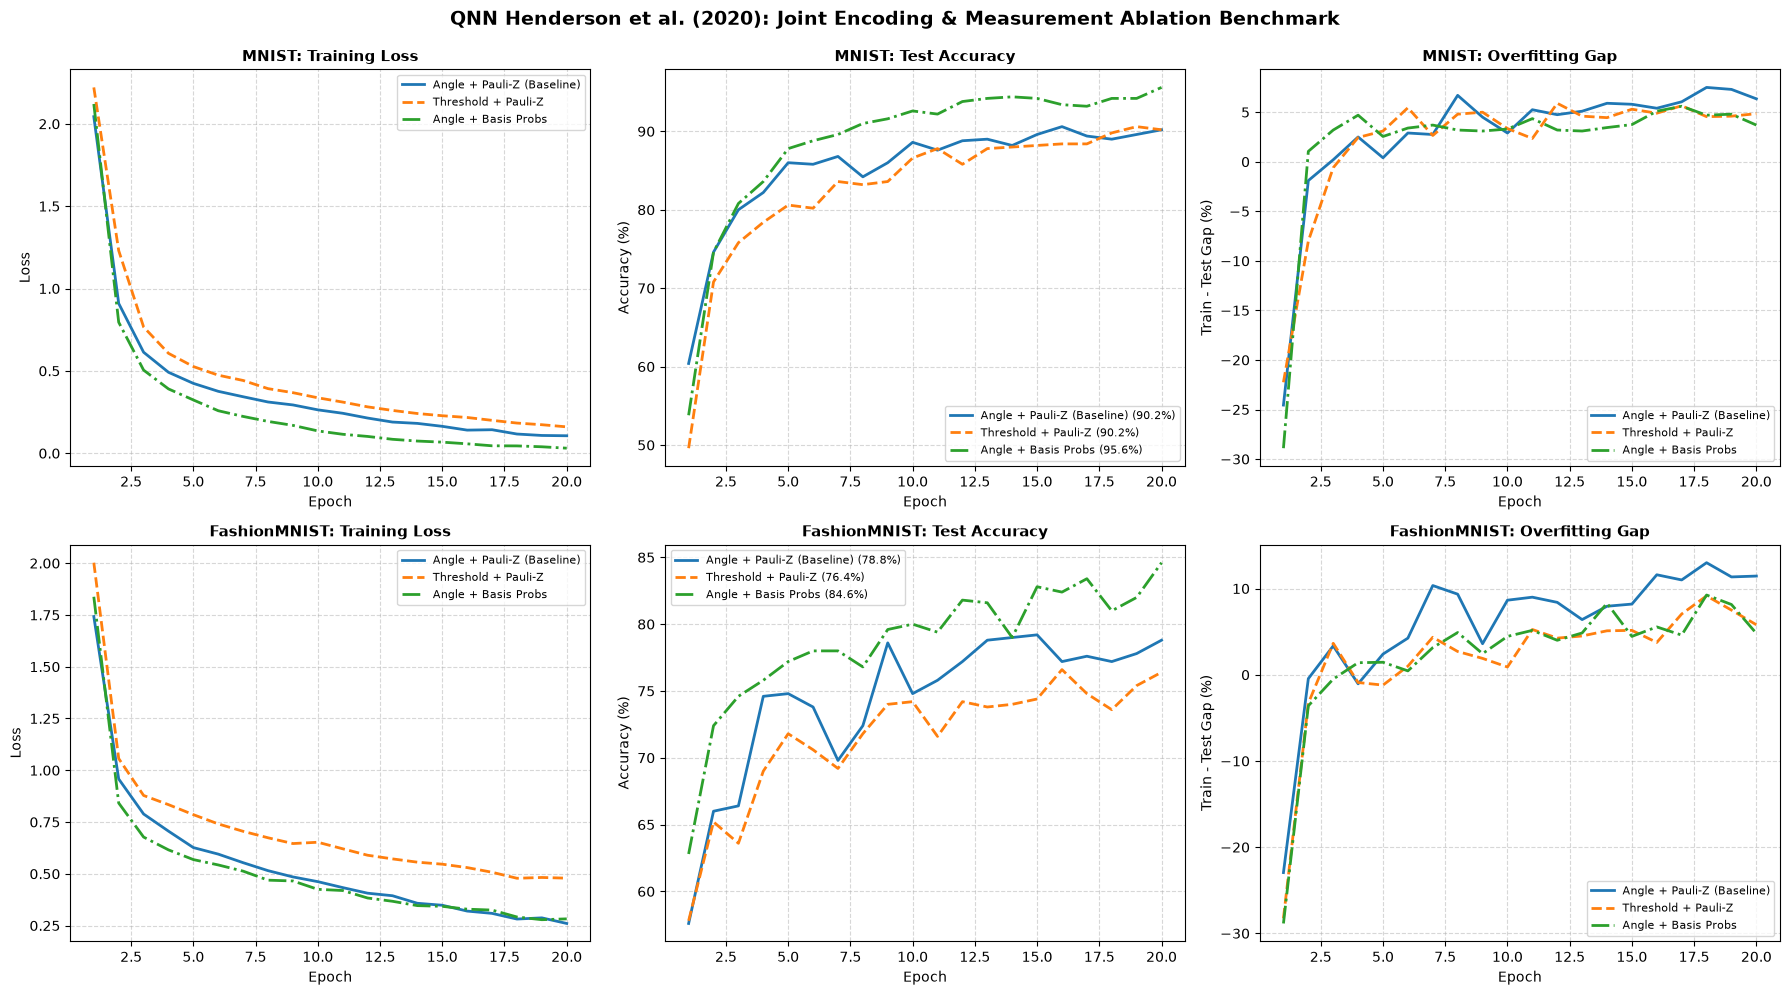

In [9]:
# Print Detailed Comparative Table
print("\n" + "=" * 100)
print(f"JOINT ABLATION BENCHMARK: ENCODING & MEASUREMENT SCHEMES (MNIST & FASHION-MNIST)")
print("=" * 100)
print(f"{'Condition':<30} | {'Channels':<8} | {'Params':<8} | {'MNIST Acc':<11} | {'MNIST Gap':<11} | {'F-MNIST Acc':<12} | {'F-MNIST Gap':<12}")
print("-" * 100)

configs = [
    ("Angle + Pauli-Z (Baseline)", 4, p_4ch),
    ("Threshold + Pauli-Z", 4, p_4ch),
    ("Angle + Basis Probs", 16, p_16ch),
]

for name, ch, p_cnt in configs:
    m_acc = all_results["MNIST"][name]["test_acc"][-1] * 100
    m_gap = all_results["MNIST"][name]["gap"][-1] * 100
    f_acc = all_results["FashionMNIST"][name]["test_acc"][-1] * 100
    f_gap = all_results["FashionMNIST"][name]["gap"][-1] * 100
    print(f"{name:<30} | {ch:<8} | {p_cnt:<8} | {m_acc:>6.2f}%    | +{m_gap:>5.2f}%   | {f_acc:>7.2f}%    | +{f_gap:>6.2f}%")
print("=" * 100)

# --- Multi-Panel Side-by-Side Visualizations ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
epochs_arr = np.arange(1, EPOCHS + 1)
colors = {
    "Angle + Pauli-Z (Baseline)": "#1f77b4",
    "Threshold + Pauli-Z": "#ff7f0e",
    "Angle + Basis Probs": "#2ca02c"
}
styles = {
    "Angle + Pauli-Z (Baseline)": "-",
    "Threshold + Pauli-Z": "--",
    "Angle + Basis Probs": "-."
}

for row_idx, ds_name in enumerate(["MNIST", "FashionMNIST"]):
    res = all_results[ds_name]
    
    # Loss
    for name, h in res.items():
        axes[row_idx, 0].plot(epochs_arr, h["loss"], label=name, color=colors[name], linestyle=styles[name], lw=2)
    axes[row_idx, 0].set_title(f"{ds_name}: Training Loss", fontsize=11, fontweight="bold")
    axes[row_idx, 0].set_xlabel("Epoch", fontsize=10); axes[row_idx, 0].set_ylabel("Loss", fontsize=10)
    axes[row_idx, 0].grid(True, linestyle="--", alpha=0.5); axes[row_idx, 0].legend(fontsize=8)

    # Test Accuracy
    for name, h in res.items():
        axes[row_idx, 1].plot(epochs_arr, [a * 100 for a in h["test_acc"]], label=f"{name} ({h['test_acc'][-1]*100:.1f}%)",
                              color=colors[name], linestyle=styles[name], lw=2)
    axes[row_idx, 1].set_title(f"{ds_name}: Test Accuracy", fontsize=11, fontweight="bold")
    axes[row_idx, 1].set_xlabel("Epoch", fontsize=10); axes[row_idx, 1].set_ylabel("Accuracy (%)", fontsize=10)
    axes[row_idx, 1].grid(True, linestyle="--", alpha=0.5); axes[row_idx, 1].legend(fontsize=8)

    # Generalization Gap
    for name, h in res.items():
        axes[row_idx, 2].plot(epochs_arr, [g * 100 for g in h["gap"]], label=name, color=colors[name], linestyle=styles[name], lw=2)
    axes[row_idx, 2].set_title(f"{ds_name}: Overfitting Gap", fontsize=11, fontweight="bold")
    axes[row_idx, 2].set_xlabel("Epoch", fontsize=10); axes[row_idx, 2].set_ylabel("Train - Test Gap (%)", fontsize=10)
    axes[row_idx, 2].grid(True, linestyle="--", alpha=0.5); axes[row_idx, 2].legend(fontsize=8)

plt.suptitle("QNN Henderson et al. (2020): Joint Encoding & Measurement Ablation Benchmark", fontsize=14, y=0.99, fontweight="bold")
plt.tight_layout()
plt.show()
